# Encoding numerical values

#### numerical --> categorical 

### 1. Discretization(Binning)
### 2. Binarization

# **1. Discretization**

transforming continuos variables into discrete variables by creating a set of contiguos intervals that span the range of the variable's value. Discretization is also called binnig, where bin is an alt name for interval.

### Why use discretization: 1. to handle outliers, 2. to improve the value spread

## Binning type : 

## 1. Unsupervised 
#### 1. Equal width 
#### 2. Equal frequency 
#### 3. K means binning 

<br><br>


## 2. Supervised 
#### 1. Decision tree binning 

<br><br>



## 3. Custom Binning 

# Equal width/ Uniform binning

### $$interval = \frac{\max(X) - \min(X)}{bins}$$

# Equal Frequency

### No of bins (intervals) prompted by the user.

### If the prompted number is 10 intervals lets say, then each interval contains 10% of total observations. The number of values in the interval is similar.

### This is also called quantile binning. It works better on outliers than equal binning and handles the value spread better.

# <br><br>

# K Means Binning



### K-Means binning is an unsupervised preprocessing technique best used when data naturally forms distinct clusters or irregular, multi-modal distributions. The algorithm begins by randomly initializing $k$ centroids across the dataset, then iteratively calculates the distance (absolute difference, $|x - c|$) between each data point and these centroids, assigning each value to its nearest center. Centroids are continuously updated to the mean of their assigned points until they stabilize. Unlike rigid mathematical splits, the final bin intervals are data-driven, defined by the exact midpoints between adjacent stable centroids ($\frac{C_A + C_B}{2}$). This makes the technique highly effective at isolating outliers into their own distinct bins rather than letting them distort uniform intervals.

<br><br>

### class sklearn.preprocessing.KBinsDiscretizer(n_bins=5, *, encode='onehot', strategy='quantile', quantile_method='averaged_inverted_cdf', dtype=None, subsample=200000, random_state=None)

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
import matplotlib.pyplot as plt 

In [3]:
from sklearn.preprocessing import KBinsDiscretizer

In [4]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer

In [5]:
df = pd.read_csv('../train.csv', usecols=['Age', 'Fare', 'Survived'])

In [6]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
df.shape

(891, 3)

In [8]:
df.dropna(inplace = True)

In [9]:
df.isna().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [10]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


# Without applying any binning 

In [11]:
X = df.drop(columns=['Survived'])

In [12]:
X.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


In [13]:
Y = df.iloc[:, 0]

In [14]:
Y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [15]:
X_train, X_test, Y_train , Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [16]:
X_train.head()

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000
719,33.0,7.7750
666,25.0,13.0000


In [17]:
clf = DecisionTreeClassifier()


In [18]:
clf.fit(X_train, Y_train)
Y_pred = clf.predict(X_test)

In [19]:
accuracy_score(Y_test, Y_pred)

0.6293706293706294

In [20]:
print(f"{np.mean(cross_val_score(DecisionTreeClassifier(), X, Y, cv=10, scoring = "accuracy" ))*100}%")

62.893192488262905%


# Applying Discretizer

In [21]:
kbin_age = KBinsDiscretizer(n_bins=15, encode= "ordinal", strategy="quantile")
kbin_fare = KBinsDiscretizer(n_bins=15, encode= "ordinal", strategy="quantile")

In [22]:
trf = ColumnTransformer([
    ('first', kbin_age, [0]), 
    ('second', kbin_fare, [1])
])

In [23]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [24]:
X_train_trf

array([[ 8.,  8.],
       [ 6.,  7.],
       [ 8.,  7.],
       ...,
       [11., 14.],
       [ 9.,  8.],
       [ 9.,  3.]], shape=(571, 2))

In [25]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=15),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=15)}

In [26]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [27]:

op = pd.DataFrame({'age': X_train['Age'], 
                  'age_trf': X_train_trf[:, 0],
                  'fare': X_train['Fare'], 
                      'fare_trf': X_train_trf[:, 1]})

In [28]:
op.head()

,age,age_trf,fare,fare_trf
328,31.0,8.0,20.5250,8.0
73,26.0,6.0,14.4542,7.0
253,30.0,8.0,16.1000,7.0
719,33.0,9.0,7.7750,2.0
666,25.0,6.0,13.0000,6.0


In [29]:
op['age_labels'] = pd.cut(x=X_train['Age'],
                                    bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
op['fare_labels'] = pd.cut(x=X_train['Fare'],
                                    bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [30]:
op.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
246,25.0,6.0,7.7750,2.0,"(23.0, 25.0]","(7.25, 7.775]"
536,45.0,12.0,26.5500,10.0,"(42.0, 47.0]","(26.0, 26.55]"
456,65.0,14.0,26.5500,10.0,"(54.0, 80.0]","(26.0, 26.55]"
548,33.0,9.0,20.5250,8.0,"(32.0, 35.0]","(18.75, 26.0]"
702,18.0,2.0,14.4542,7.0,"(16.0, 19.0]","(13.0, 14.454]"


In [31]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf, Y_train)
Y_pred2 = clf.predict(X_test_trf)

In [32]:
accuracy_score(Y_test, Y_pred2)

0.6363636363636364

In [33]:
print(f"{np.mean(cross_val_score(DecisionTreeClassifier(), X, Y, cv=10, scoring = "accuracy" ))*100}%")

63.450704225352105%


In [36]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()

0.6331181533646323


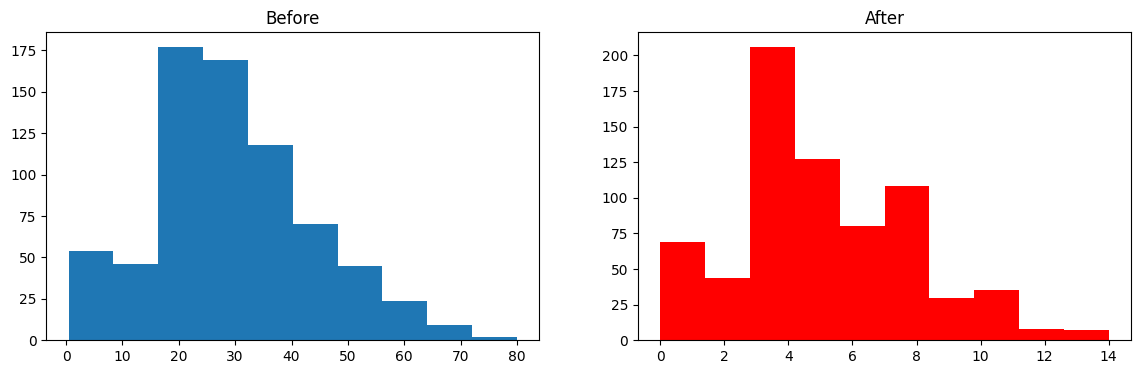

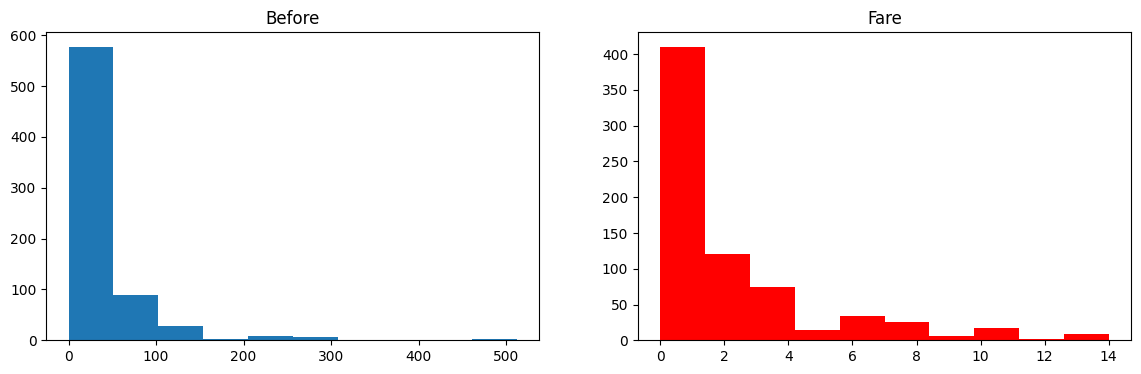

In [39]:
discretize(15, 'kmeans')

<br><br>

# Custom/Domain based Binning 

### Binning on your own. Like binning age based on kids, adult, oldage etc.

<br><br>

# Binarization

### Converting a continuos value in binarized form (0,1). Eg: salary in taxable bracket or not.

### using binarizer class in scikitlearn(threshold = int, copy = bool)